# Options pricing and hedging
George Dharma

**How accurately can we price a European put, and how much protection does a
delta hedge provide after trading costs?** Python answers both questions here.

A put pays when the underlying finishes below its strike. This example has a
$40 strike, a $36 starting asset price and one year to expiry. If the asset
ends at $35, one put unit pays $5. European exercise means exercise occurs only
at expiry. The hypothetical contract is cash settled.

The starting parameters come from QuantLib's published EquityOption example.
They are an illustrative valuation case, not current market data. The bid–ask
quotes and future price paths below are also illustrative. Use the complete project folder when rerunning this notebook. See [run instructions](../docs/RUNNING.md).

## Reading this notebook

Read from top to bottom. The sections below show the order of the analysis. Tables and charts are saved in the notebook. To recalculate, restart the Python kernel and run all cells; the first code cell runs the full experiment.

- 1  Compare three methods on the same contract
- 2  Understand the risk sensitivities
- 3  Recover implied volatility from a price
- 4  Follow the cash, shares and option together
- 5  Compare schedules using the same paths
- 6  Test model mismatch and jumps
- 7  Decision
- Sources and running the project

[Project introduction](../README.md) · [Run instructions](../docs/RUNNING.md) · [Detailed methodology](../docs/METHODOLOGY.md)

In [1]:
from pathlib import Path
import sys

ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "options").is_dir() and (folder / "data").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Extract the complete project ZIP and open its notebooks folder."
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from dataclasses import replace
import numpy as np
import pandas as pd
from IPython.display import Image, display
from options.engine import Option, price, greeks, implied_volatility
from options.analysis import run

pd.set_option("display.max_columns", 12)
result = run(ROOT)
option = Option(**result["assumptions"]["option"])
print(option)
print(f"Put value: ${float(price(option)):.8f} per unit")
print("Position: sell 100 contracts × 100 units = 10,000 put units")


Option(spot=36.0, strike=40.0, years=1.0, rate=0.06, dividend=0.0, volatility=0.2, kind='put')
Put value: $3.84430779 per unit
Position: sell 100 contracts × 100 units = 10,000 put units


## 1  Compare three methods on the same contract

**Black–Scholes** gives an analytical value under constant volatility, a
constant interest rate and continuous price changes. A **binomial tree** builds
up/down price steps and works backward from the final payoff. **Monte Carlo**
simulates final prices and averages discounted payoffs.

For a put, the analytical value is
$$P=K e^{-rT}N(-d_2)-S e^{-qT}N(-d_1),$$
where $d_1=[\ln(S/K)+(r-q+\sigma^2/2)T]/(\sigma\sqrt T)$ and
$d_2=d_1-\sigma\sqrt T$. Here $N$ is the cumulative standard normal
distribution, $r$ the funding rate, $q$ the dividend yield and $\sigma$ annual
volatility. The engine also supports calls and nonzero dividends for pricing.
The hedge experiment specifically assumes zero dividends.

The Monte Carlo model uses the risk-free rate in its price drift. This is a
valuation convention, not a forecast of the asset's investment return.

,method,size,price,error,runtime_ms
0,Black–Scholes,0,3.844308,0.000000,0.017066
1,CRR tree,25,3.842173,-0.002135,0.127172
2,CRR tree,50,3.839611,-0.004697,0.237238
3,CRR tree,100,3.848396,0.004088,0.484370
4,CRR tree,200,3.845417,0.001109,0.970513
5,CRR tree,400,3.844794,0.000486,1.258578
6,CRR tree,800,3.844920,0.000613,4.394274
7,CRR tree,1600,3.844619,0.000311,9.805461
8,CRR tree,3200,3.844181,-0.000127,22.409401



Monte Carlo: independent antithetic pairs


,pairs,paths,price,standard_error,ci_low,ci_high,error,runtime_ms
0,1000,2000,3.795953,0.049696,3.698432,3.893474,-0.048355,0.222646
1,10000,20000,3.848441,0.015756,3.817555,3.879326,0.004133,0.402777
2,100000,200000,3.849074,0.004947,3.839379,3.858769,0.004766,3.681289
3,500000,1000000,3.845259,0.002202,3.840942,3.849575,0.000951,19.251511


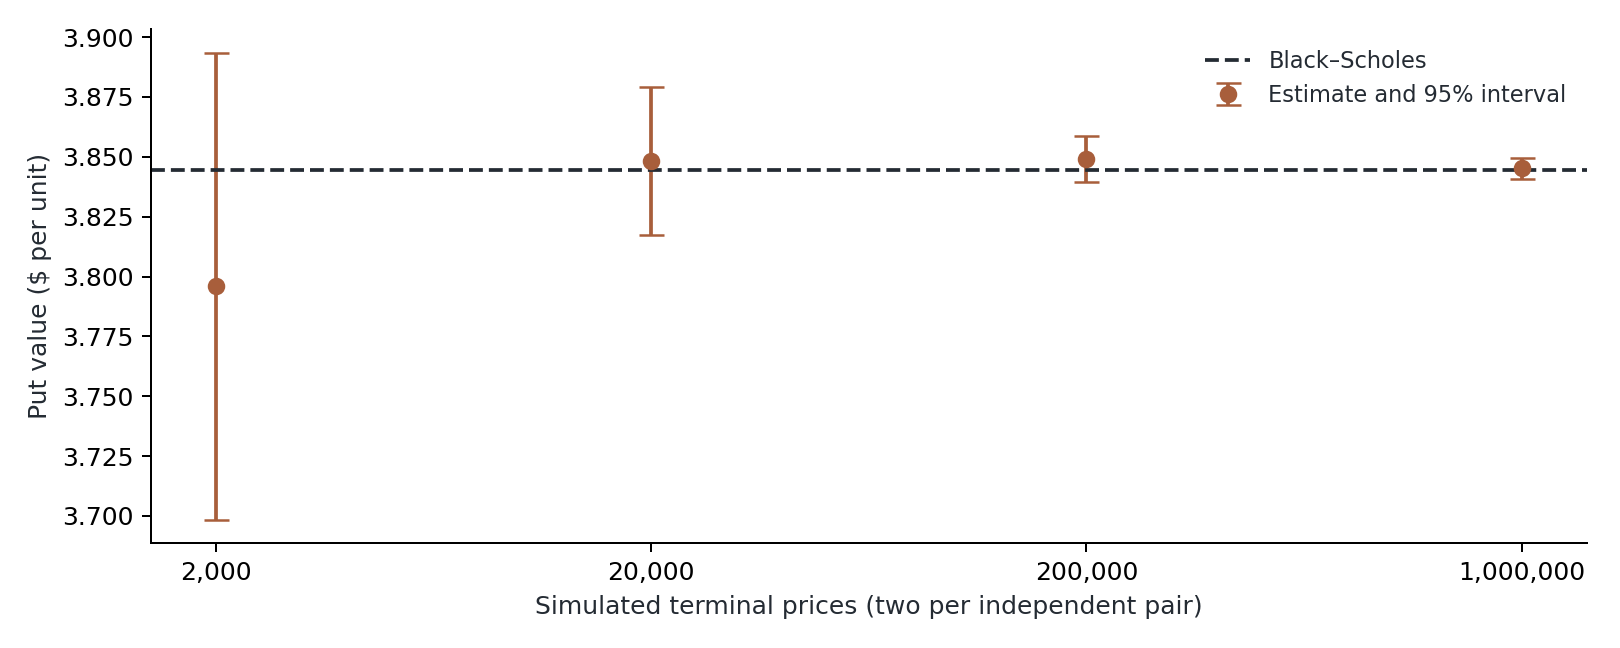

In [2]:
display(pd.DataFrame(result["pricing"]).round(8))
print("\nMonte Carlo: independent antithetic pairs")
display(pd.DataFrame(result["monte_carlo"]).round(8))
display(Image(filename=str(ROOT / "outputs/pricing_convergence.png")))


Each random draw is paired with its negative to reduce sampling noise.
The two resulting payoffs are averaged first. The confidence interval uses
the number of independent **pairs**, not the larger count of correlated paths.
It measures simulation uncertainty conditional on the model.

More tree steps generally improve accuracy, but the error oscillates as the
strike falls between different nodes. More Monte Carlo paths narrow the
confidence interval; they do not guarantee that every new estimate is closer.
Timings are warmed median wall-clock measurements in this Python environment,
excluding file access and plotting. They are not universal speed claims.

## 2  Understand the risk sensitivities

**Delta** estimates the option price change for a $1 underlying-price move.
**Gamma** measures the change in delta per $1. **Vega** here is the price
change for a one-percentage-point volatility increase, such as 20% to 21%.
**Theta** is the change per calendar day passing. **Rho** is the change for
a one-percentage-point interest-rate increase. All refer to one long put unit.

The finite-difference calculation changes an input slightly and reprices.
This provides a second route to each sensitivity. The chosen steps are
0.01% of spot, 0.01 percentage point for volatility and rates, and 0.1 calendar
day for time. Central differences use an up and a down move.

In [3]:
display(pd.DataFrame(result["greeks"]))
print("\nLarger changes: dollars per long put unit")
display(
    pd.DataFrame(result["scenarios"])[
        ["scenario", "exact", "first_order", "with_gamma", "residual"]
    ].round(6)
)


,greek,analytical,finite_difference,difference
0,delta,-0.550452,-0.550452,-1.206572e-09
1,gamma,0.054965,0.054965,-8.040252e-10
2,vega,0.142469,0.142469,-9.651061e-10
3,theta,-0.000014,-0.000014,-7.159329e-12
4,rho,-0.236606,-0.236606,-8.285994e-10



Larger changes: dollars per long put unit


,scenario,exact,first_order,with_gamma,residual
0,Spot −10%,2.334438,1.981626,2.337799,-0.003361
1,Spot +10%,-1.636356,-1.981626,-1.625453,-0.010903
2,Volatility +5 pp,0.715052,0.712346,0.712346,0.002706
3,"Spot −10%, volatility +5 pp",2.886404,2.693972,3.050145,-0.163741


The first-order estimate uses delta and vega. Adding gamma helps with a
large spot move. The combined spot-and-volatility shock still has a noticeable
residual: this approximation excludes volatility curvature and interactions
between spot and volatility. Full repricing captures those effects.

The near-zero initial theta is a feature of this particular put and interest
rate. It is not a rule that options lose little value as time passes.

## 3  Recover implied volatility from a price

**Implied volatility** is the volatility input that makes the model match an
option price. The exercise below uses a constructed $3.80 bid and $3.90 ask
for the same put at time zero. The matching underlying is $36; rates, strike,
maturity and exercise style remain fixed. These are not downloaded quotes.

The solver checks European price bounds before searching. Bid and ask produce
a volatility interval; using the midpoint gives one summary estimate. That
interval reflects the assumed spread, not a statistical confidence interval.

Cboe's public data specification distinguishes the 15:45 snapshot from the
end-of-day snapshot. It also notes that underlying quotes can be missing.
Its sample ZIP returned HTTP 403 in this environment, so no Cboe market
calibration is claimed here.

In [4]:
display(pd.DataFrame(result["quotes"]))
for row in result["quotes"]:
    assert abs(row["repriced"] - row["premium"]) < 1e-09
print("\nEach recovered volatility reproduces its input premium.")


,side,premium,implied_volatility,repriced
0,Bid,3.80,0.196889,3.80
1,Mid,3.85,0.200400,3.85
2,Ask,3.90,0.203908,3.90



Each recovered volatility reproduces its input premium.


## 4  Follow the cash, shares and option together

The position sells 10,000 put units and receives the model premium. Because
a long put has negative delta, its replicating hedge holds **negative shares**:
it shorts the underlying. The short put plus those shares starts near zero
net delta. Short-sale proceeds remain in the cash account; they are not profit.

At each hedge date, share holdings become $h_t=10{,}000\,\Delta_t$.
The cash account first earns or pays interest, then funds the share trade and
its cost. A 5 bp one-way trading cost means 0.05% of the absolute amount traded.
Entry, every rebalance and final liquidation are charged.

At expiry, the model closes the share position and pays the put payoff. The
remaining cash is terminal profit or loss (**P&L**). No extra cash is injected.
The model assumes the asset can be traded and shorted, with borrowing and
lending at 6%, no additional stock-borrow fee and no margin constraint.

In [5]:
ledger = pd.DataFrame(result["journal"])
selected = ledger[ledger.day.isin([0, 1, 5, 250, 252])]
display(
    selected[
        [
            "day",
            "spot",
            "trade_shares",
            "trading_cost",
            "interest",
            "cash_close",
            "net_value",
        ]
    ].round(4)
)
reconstructed = (
    ledger.cash_open
    + ledger.interest
    - ledger.trade_shares * ledger.spot
    - ledger.trading_cost
    - ledger.option_settlement
)
assert np.allclose(ledger.cash_close, reconstructed, atol=1e-08)
print(f"\nOne sample path ends with P&L of ${ledger.net_value.iloc[-1]:,.2f}.")


,day,spot,trade_shares,trading_cost,interest,cash_close,net_value
0,0,36.0000,-5504.5167,99.0813,0.0000,236506.5987,-99.0813
1,1,35.2433,0.0000,0.0000,56.3178,236562.9165,-205.9399
5,5,35.1664,-499.6307,8.7851,56.3715,254349.7294,-48.2446
250,250,36.3236,-12.3656,0.2246,95.2761,400656.4036,846.8483
252,252,37.1061,9999.9996,185.5306,95.4285,661.7213,661.7213



One sample path ends with P&L of $661.72.


## 5  Compare schedules using the same paths

Each case has 30,000 independent price paths with 252 sessions over one year.
All four policies use exactly the same paths within a case. The experiment
compares no hedge, a rebalance every 21 sessions, every 5 sessions and every
session. These intervals approximate monthly, weekly and daily trading.

Standard deviation describes the spread of terminal outcomes. The 5th
percentile is a loss threshold exceeded on roughly 5% of paths. The
**worst-5% average** averages the 1,500 lowest P&Ls, so it describes losses
beyond that threshold. All amounts include trading costs and their financing.

,policy,mean,std,p05,tail_mean,mean_cost_fv
0,Unhedged,-96.46,46085.81,-90169.92,-110995.30,0.00
1,Every 21 sessions,-407.32,7441.89,-12842.16,-18330.16,407.76
2,Every 5 sessions,-611.54,3696.14,-6868.61,-9402.27,639.77
3,Every session,-1148.90,1746.50,-4207.28,-5477.49,1166.54


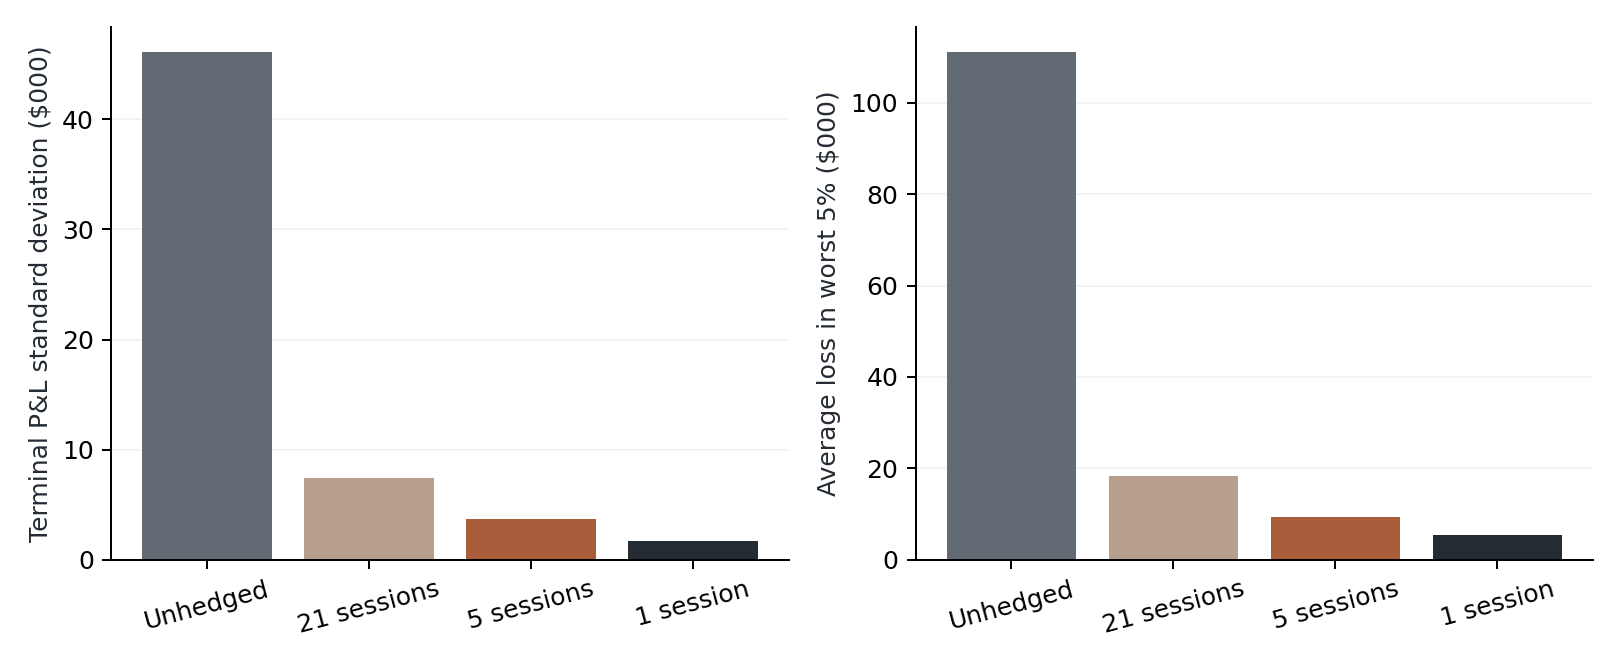


Cost sensitivity: average P&L / worst-5% average


,policy,cost_bps,mean,tail_mean
0,Unhedged,0,-96.46,-110995.30
1,Unhedged,1,-96.46,-110995.30
2,Unhedged,5,-96.46,-110995.30
3,Unhedged,10,-96.46,-110995.30
4,Every 21 sessions,0,0.43,-17836.21
5,Every 21 sessions,1,-81.12,-17934.85
6,Every 21 sessions,5,-407.32,-18330.16
7,Every 21 sessions,10,-815.08,-18825.67
8,Every 5 sessions,0,28.22,-8556.62
9,Every 5 sessions,1,-99.73,-8724.92


In [6]:
hedges = pd.DataFrame(result["hedging"])
display(
    hedges[hedges["case"] == "Base"][
        ["policy", "mean", "std", "p05", "tail_mean", "mean_cost_fv"]
    ].round(2)
)
display(Image(filename=str(ROOT / "outputs/hedge_comparison.png")))
print("\nCost sensitivity: average P&L / worst-5% average")
display(
    pd.DataFrame(result["cost_sensitivity"])[
        ["policy", "cost_bps", "mean", "tail_mean"]
    ].round(2)
)


Daily hedging has the lowest base-case dispersion and lowest average loss
in the worst 5% among these schedules. It also trades more and has a more
negative average P&L after costs. Selling at the model value provides no
extra premium to cover those costs. This is a risk-reduction comparison, not
a profitable trading strategy.

The paired daily-minus-five-session mean difference is calculated path by
path. Its confidence interval measures simulation uncertainty around that
mean difference; it does not measure uncertainty about future markets.

In [7]:
display(
    pd.DataFrame(result["paired"])[
        ["case", "mean", "mean_ci_low", "mean_ci_high"]
    ].round(2)
)


,case,mean,mean_ci_low,mean_ci_high
0,Base,-537.36,-575.50,-499.22
1,Higher volatility,-673.64,-746.82,-600.46
2,Jumps,-488.32,-542.25,-434.38


## 6  Test model mismatch and jumps

In the higher-volatility case, paths use 30% volatility but the sold premium
and hedge deltas still use 20%. In the jump case, diffusion volatility stays
at 20%, with one jump per year on average. Log jump size has mean −0.10 and
standard deviation 0.15. The mean percentage jump is therefore about −8.49%,
not −10%. An adjustment to the drift preserves the expected asset growth at
the risk-free rate. These are prespecified illustrative stresses.

The hedge sees only the current spot and remaining time at each scheduled
date. A sudden jump can occur before the next adjustment, leaving a loss
that more frequent delta trading cannot fully remove.

,case,policy,mean,std,tail_mean
0,Base,Unhedged,-96.46,46085.81,-110995.30
1,Base,Every 21 sessions,-407.32,7441.89,-18330.16
2,Base,Every 5 sessions,-611.54,3696.14,-9402.27
3,Base,Every session,-1148.90,1746.50,-5477.49
4,Higher volatility,Unhedged,-15336.16,62862.08,-161825.02
5,Higher volatility,Every 21 sessions,-15639.78,13638.21,-53464.11
6,Higher volatility,Every 5 sessions,-15874.83,9532.31,-39895.41
7,Higher volatility,Every session,-16548.47,8435.46,-35211.95
8,Jumps,Unhedged,-8540.91,59486.95,-159742.03
9,Jumps,Every 21 sessions,-8680.90,16489.19,-59585.61


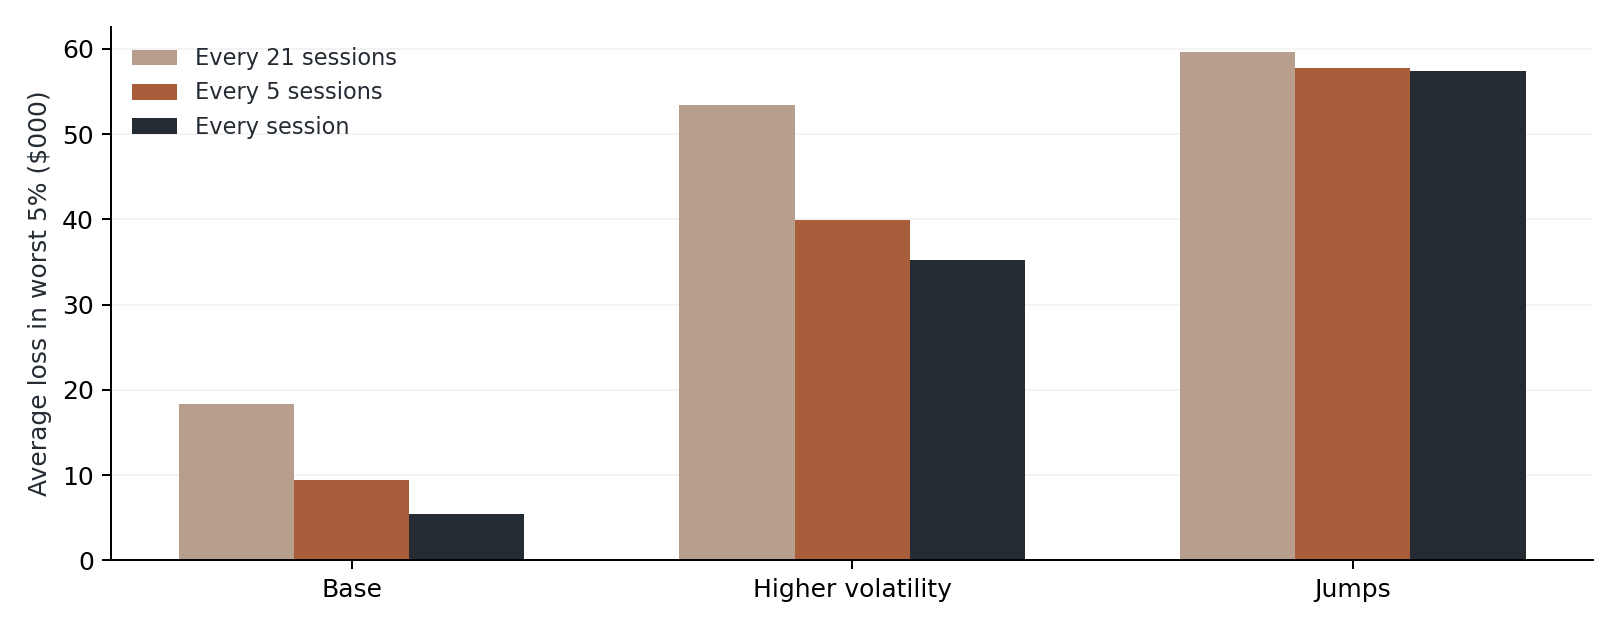


Discounted terminal asset mean; theoretical value is $36


,case,discounted_terminal_mean,standard_error
0,Base,36.011854,0.042191
1,Higher volatility,36.022805,0.064058
2,Jumps,36.016750,0.054384


In [8]:
display(hedges[["case", "policy", "mean", "std", "tail_mean"]].round(2))
display(Image(filename=str(ROOT / "outputs/stress_comparison.png")))
print("\nDiscounted terminal asset mean; theoretical value is $36")
display(pd.DataFrame(result["path_checks"]))


## 7  Decision

For the stated aim of reducing terminal loss dispersion in the base model,
daily delta hedging is the strongest of the tested schedules. It reduces the
worst-5% average loss from about $9,402 with five-session hedging to $5,477,
while increasing average terminal-value costs from about $640 to $1,167.

The jump case still has a daily worst-5% average loss near $57,433. Increasing
frequency alone does not address the full gap between the pricing model and
the stressed price process. The 30% volatility case similarly loses money
because the option was sold using a 20% volatility price. These results
support daily hedging as a baseline risk control, with explicit cost and model
risk monitoring. They do not establish an optimal policy for all markets.

## Sources and running the project

- [QuantLib EquityOption example, pinned version](https://github.com/lballabio/QuantLib/blob/e4090768195f9c5b0bf8a6d0cb6802238342c50d/Examples/EquityOption/EquityOption.cpp): common pricing inputs and method comparison.
- [Goldman Sachs scenario examples](https://developer.gs.com/docs/gsquant/pricing-and-risk/scenarios/): compare repricing with sensitivity estimates. This project implements its own calculations and does not use the GS service.
- [Bühler and coauthors, Deep Hedging](https://arxiv.org/abs/1802.03042): research context for evaluating hedges with trading frictions. This project implements a transparent delta baseline, not a neural network.
- [Cboe Option EOD Summary layout](https://datashop.cboe.com/documents/Option_EOD_Summary_Layout.pdf): snapshot and underlying-price requirements.

Run `python -m unittest discover -s tests -v` for 20 tests. They cover
put–call parity, expiry, price bounds, Greeks, pricing convergence, implied
volatility, financing, transaction costs, position scaling and absence of
future information in hedge decisions. The Excel pricing and IV calculations
are live. Its simulation comparison is a saved Python output; rerun Python to
change the simulation assumptions.